# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [117]:
# importar librerías
import pandas as pd 
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency
import seaborn as sns 
import matplotlib.pyplot as plt

In [76]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [77]:
# mostrar las primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [78]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB



 Se observa una inconformidad en la columna date, ya que esta se presenta como  tipo object y deberia ser tipo date. El resto de datos se presentan correctamente.  

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:
- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [79]:
df['user_id'].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [80]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [81]:
#Cambio de tipo de datos, paso de object a date time la columan fecha 
df['date']=pd.to_datetime(df['date'])
df.dtypes

user_id                   object
date              datetime64[ns]
landing                   object
region                    object
dispositivo               object
traffic_source            object
user_type                 object
converted                  int64
gasto                    float64
dtype: object

In [82]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [83]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [84]:
# Resumen estadístico de usuarios que se convirtieron
df['converted'].value_counts()

0    34294
1     5706
Name: converted, dtype: int64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [85]:

# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")

print(df['landing'].value_counts())


Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64


In [86]:
print(df['user_type'].value_counts())

Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


In [87]:
print('\nConteo de categorias:')
print(df['region'].value_counts())


Conteo de categorias:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64


In [88]:
print('\n Conteo de Categorias:')
print (df['traffic_source'].value_counts())


 Conteo de Categorias:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64


- Todas las columnas tienen valores esperados, se evidencia en conteo de categorias de `landing`,unicamente las categorias  A y B correctamente. Lo mismo sucede para la categoria `user_type`, unicmanete se evidencia nuevo y recurrente



## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [89]:

# Gasto por versión
print('\nGasto promedio de usuarios que se convirtieron en clientes en página A')
gasto_A = df[(df['landing']=='A') & (df['converted']==1)]['gasto']
print(gasto_A.describe())

print()
print('\nGasto promedio de usuarios que se convirtieron en clientes en página B')
gasto_B = df[(df['landing']=='B') & (df['converted']==1)]['gasto']
print(gasto_B.describe())

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)



Gasto promedio de usuarios que se convirtieron en clientes en página A
count    2512.000000
mean       61.086572
std        28.875470
min        12.120000
25%        40.612500
50%        55.840000
75%        74.837500
max       303.680000
Name: gasto, dtype: float64


Gasto promedio de usuarios que se convirtieron en clientes en página B
count    3194.00000
mean       68.74536
std        32.00102
min        12.98000
25%        45.21000
50%        62.57000
75%        84.27750
max       249.99000
Name: gasto, dtype: float64


(2512, 3194)

### Prueba T test 

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios que se convirtieron en clientes es el mismo para la página A y la página B
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios que se convirtieron en clientes para la página B es mayor

In [90]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B)



# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor p: {p_value}")

Estadístico t: -9.36563589591332
Valor p: 1.0635288333792346e-20


### 📝 Conclusión e interpretación

**Decisión:**  
DE acuerdo al valor del P_value, este al serun p value bajo nos permite rechazar la hipotesis nula.

**Interpretación de negocio:**  
Con base en los resultados estadisticos obtenidos de la prueba t test, en donde rechazamos la hipotesis nula se puede concluir que el gasto promedio entre la página A y la página B es diferente, en otras palabras el gasto promedio de los usuarios de la pagina B es mayor.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en ambas paginas. Cualquier diferencia se debe al azar del muestreo.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre ambas páginas. Hay un factor que genera mayor número de usuarios convertidos.

In [100]:

# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n",conversiones)
print("\nTotal de usuarios por página:\n", totales)

exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'],totales['B']]

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [106]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos, observaciones)


# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")
alpha = 0.05 #umbral de significacia 
if p_value < alpha:
    print('Se rechaza la hipotesis nula: hay evidencia de un factor que influye en el número de usuarios convertidos')
else:
    print('No se rechaza la hipotesis nula: no hay evidencia suficiente de que existe algún factor que influya en el número de usuarios convertidos')


Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22
Se rechaza la hipotesis nula: hay evidencia de un factor que influye en el número de usuarios convertidos


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula.

**Interpretación de negocio:**  
Se rechaza la hipotesis nula debido a que el p_value es menor al alpha, lo que nos indica que si hay un factor que influye en el número de usuarios convertidos.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi cuadrado 
**Hipótesis:**
- **Hipótesis nula (H₀):** No existe relación significativa entre la fuente de tráfico y la conversión 
- **Hipótesis alternativa (H₁):** Existe una relación entre la fuente de tráfico y la conversión 

In [109]:
tabla = pd.crosstab(df['traffic_source'], df['converted'])
print(tabla)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [111]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f'\nEstadistico chi-cuadrado:{chi2_stat:3f}')
print(f'Valor P:{p_value:3f}')
alpha = 0.05
if p_value< alpha:
    print('Se rechaza la hipotesis nula: hay evidencia de relación entre la fuente de tráfico y la conversión')
else:
    print('No se rechaza la hipotesis nula: No hay evidencia de relación suficiente entre la fuente de tráfico y la conversión ')



Estadistico chi-cuadrado:8.662109
Valor P:0.034138
Se rechaza la hipotesis nula: hay evidencia de relación entre la fuente de tráfico y la conversión


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipotesis nula

**Interpretación de negocio:**  
Se rechaza la hipotesis nula ya que el p_value es menor al alpha de 0.05 lo que nos indica que existe una asociación suficiente entre la fuente del tráfico y la conversión


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi cuadrado

**Hipótesis:**

- **Hipótesis nula (H₀):** No existe relación significativa entre tipo de usuario y conversión 
- **Hipótesis alternativa (H₁):** Existe una relación entre tipo de usuario y conversión 

In [112]:
tabla_usuario = pd.crosstab(df['user_type'], df['converted'])
print(tabla_usuario)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [115]:
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_usuario)
print(f'\nEstadistico chi-cuadrado:{chi2_stat:3f}')
print(f'Valor P:{p_value:3f}')
alpha = 0.05
if p_value< alpha:
    print('Se rechaza la hipotesis nula: hay evidencia de relación entre el tipo de usuario y la conversión')
else:
    print('No se rechaza la hipotesis nula: No hay evidencia de relación suficiente entre el tipo de usuario y la conversión ')



Estadistico chi-cuadrado:0.513485
Valor P:0.473634
No se rechaza la hipotesis nula: No hay evidencia de relación suficiente entre el tipo de usuario y la conversión 


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipotesis nula

**Interpretación de negocio:**  
No se rechaza la hipotesis nula puesto que el p_value (0.47) es mayor que el alpha (0.05), lo que nos indica que no hay evidencia significativa entre el tipo de usuario y la conversión

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

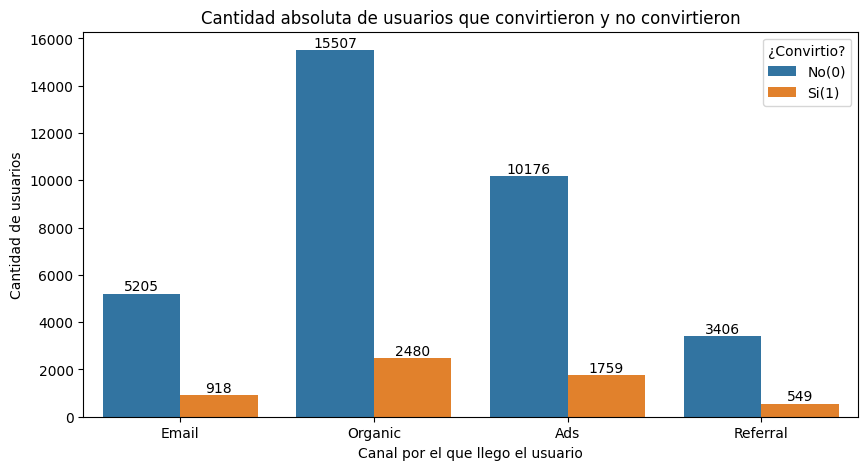

In [141]:
#grafico de barras agrupadas para ver diferencias entre grupos
plt.figure(figsize = (10,5))
#agregar valores a las barras
ax = sns.countplot(data=df, x='traffic_source', hue='converted')
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width()/2,
           y=height,
           s=height,
           ha='center',
           va='bottom')
#añadir detalles a la grafica 
plt.title('Cantidad absoluta de usuarios que convirtieron y no convirtieron')
plt.xlabel('Canal por el que llego el usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Convirtio?', labels=['No(0)', 'Si(1)'])
plt.show()




✍️ **Comentario**: En este gráfico se observa que Organic es la fuente de tráfico con mayor cantidad de usuarios, tanto entre quienes convirtieron como entre quienes no convirtieron. También es el canal que genera el mayor número absoluto de conversiones, con 2.480 usuarios convertidos, seguido por Ads, con 1.759 conversiones.

Sin embargo, al analizar únicamente las cantidades absolutas, es importante tener en cuenta que algunos canales tienen mayor volumen de usuarios que otros. Por esta razón, para identificar qué fuente es realmente más efectiva en términos de conversión, es necesario complementar este análisis con el gráfico de proporciones.



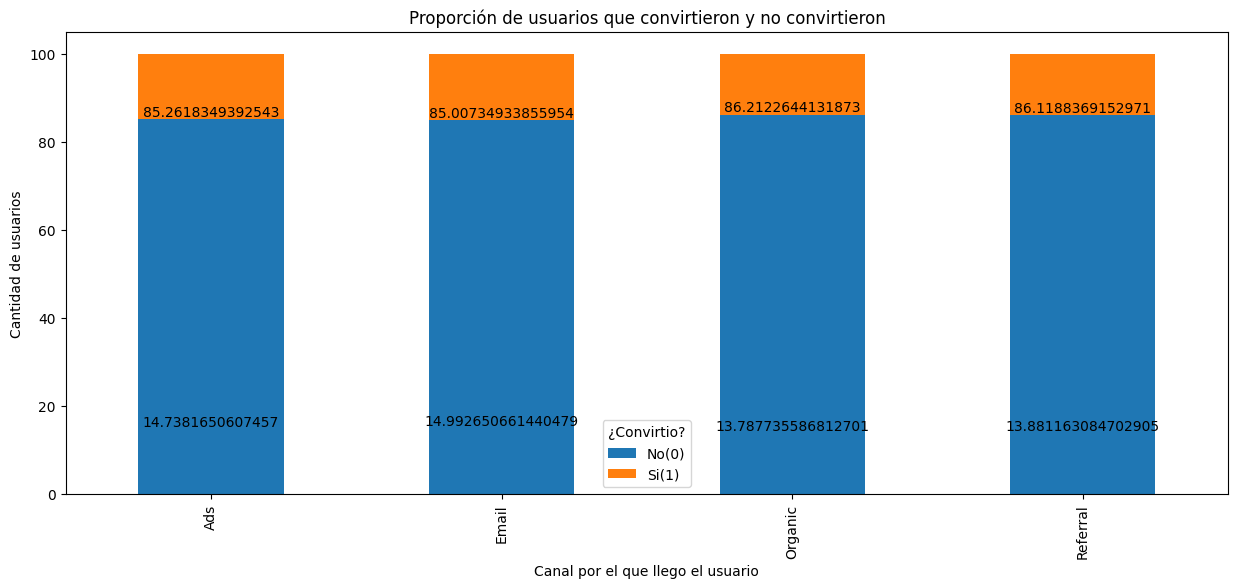

In [140]:
#grafico de barras apiladas para comparar proporciones
tabla_grafico = pd.crosstab(df['traffic_source'], df['converted'], normalize='index')*100
#agregar valores a las barras
ax= tabla_grafico.plot(kind='bar', stacked=True, figsize=(15,6))
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width()/2,
           y=height,
           s=height,
           ha='center',
           va='bottom')
#añadir detalles a la grafica 
plt.title('Proporción de usuarios que convirtieron y no convirtieron')
plt.xlabel('Canal por el que llego el usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Convirtio?', labels=['No(0)', 'Si(1)'])
plt.show()



✍️ **Comentario**: Al observar las proporciones, se evidencia que las diferencias entre los canales no son muy grandes, aunque Email presenta la mayor proporción de usuarios que convierten, con aproximadamente un 15 %, seguido muy de cerca por Ads, con 14,7 %. Por otro lado, Organic y Referral presentan tasas de conversión ligeramente menores, cercanas al 13,8 %.

Esto permite ver que, aunque Organic genera la mayor cantidad total de conversiones debido a su alto volumen de tráfico, no necesariamente es el canal más efectivo proporcionalmente. Además, estos resultados son coherentes con la prueba chi-cuadrado realizada anteriormente, en la que se encontró evidencia de una relación estadísticamente significativa entre la fuente de tráfico y la conversión.


### Relación entre el tipo de usuario y la conversión

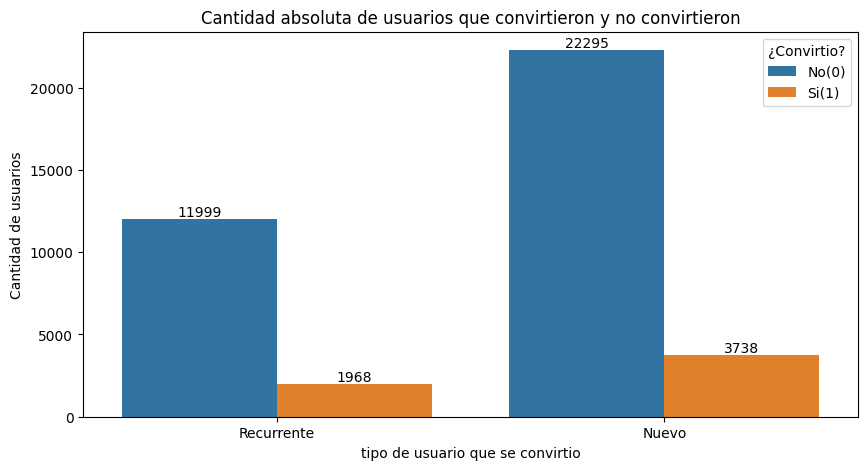

In [142]:
#grafico de barras agrupadas para ver diferencias entre grupos
plt.figure(figsize = (10,5))
#agregar valores a las barras
ax = sns.countplot(data=df, x='user_type', hue='converted')
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width()/2,
           y=height,
           s=height,
           ha='center',
           va='bottom')
#añadir detalles a la grafica 
plt.title('Cantidad absoluta de usuarios que convirtieron y no convirtieron')
plt.xlabel('tipo de usuario que se convirtio')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Convirtio?', labels=['No(0)', 'Si(1)'])
plt.show()

✍️ **Comentario**: En términos de cantidad absoluta, los usuarios nuevos representan el grupo más grande de la muestra, por lo que también presentan una mayor cantidad de conversiones: 3.738 usuarios nuevos convirtieron, frente a 1.968 usuarios recurrentes.

Sin embargo, esta diferencia parece estar relacionada principalmente con el hecho de que hay una mayor cantidad de usuarios nuevos dentro de los datos analizados. Por ello, para comparar de manera más adecuada el comportamiento de ambos grupos, es necesario observar la proporción de conversión de cada tipo de usuario.


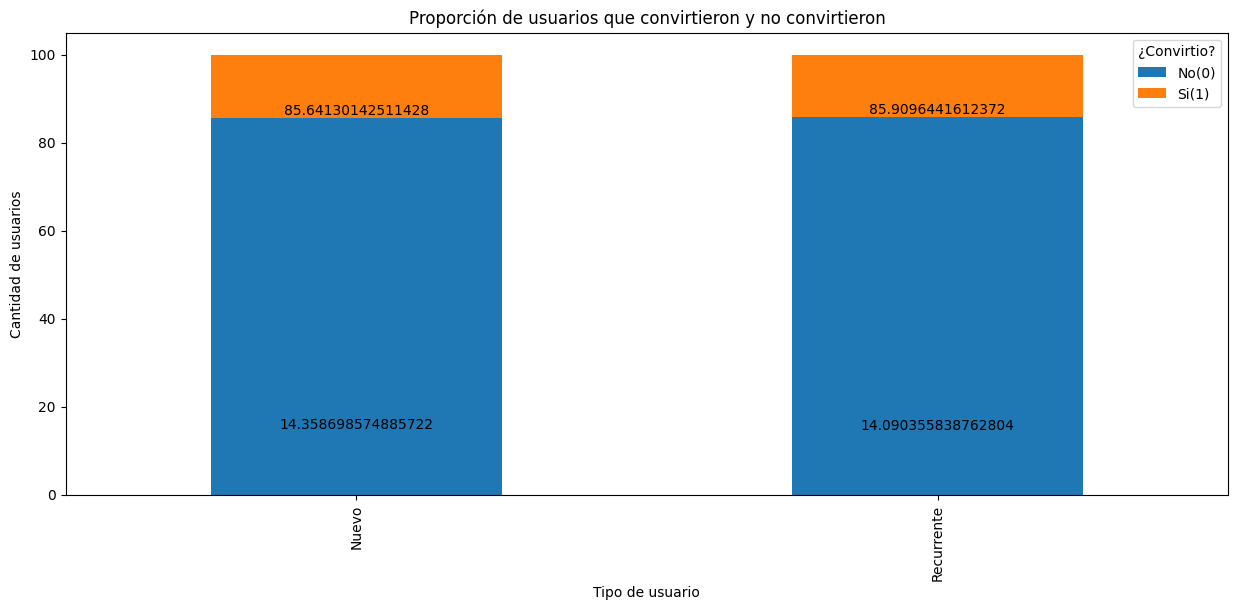

In [144]:
#grafico de barras apiladas para comparar proporciones
tabla_grafico = pd.crosstab(df['user_type'], df['converted'], normalize='index')*100
#agregar valores a las barras
ax= tabla_grafico.plot(kind='bar', stacked=True, figsize=(15,6))
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width()/2,
           y=height,
           s=height,
           ha='center',
           va='bottom')
#añadir detalles a la grafica 
plt.title('Proporción de usuarios que convirtieron y no convirtieron')
plt.xlabel('Tipo de usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Convirtio?', labels=['No(0)', 'Si(1)'])
plt.show()

✍️ **Comentario**: Al comparar las proporciones, se observa que los resultados son muy similares entre ambos grupos. Los usuarios nuevos presentan una tasa de conversión aproximada del 14,4 %, mientras que los usuarios recurrentes tienen una tasa cercana al 14,1 %.

La diferencia es mínima, lo cual coincide con el resultado de la prueba chi-cuadrado realizada anteriormente, donde no se encontró evidencia estadística suficiente para afirmar que exista una relación significativa entre el tipo de usuario y la conversión. Por lo tanto, dentro de este experimento, ser un usuario nuevo o recurrente no parece ser un factor determinante para explicar la conversión.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La página B presentó un gasto promedio mayor entre los usuarios que realizaron una conversión, con aproximadamente 68,75, frente a 61,09 en la página A.

- La diferencia observada entre ambas páginas es de aproximadamente 7,66 por usuario convertido y, de acuerdo con la prueba t realizada, esta diferencia es estadísticamente significativa, ya que el valor p fue mucho menor a 0,05.

- **Interpretación:** La versión B no solo logra que más usuarios conviertan, sino que además los usuarios que convierten tienden a realizar un gasto promedio más alto. Por lo tanto, la página B muestra un mejor desempeño en términos de ingresos generados por conversión.

**Tasa de conversión:** 
- La página A tuvo 2.512 conversiones de 19.982 usuarios, lo que representa una tasa de conversión aproximada del 12,57 %.
- La página B tuvo 3.194 conversiones de 20.018 usuarios, alcanzando una tasa de conversión aproximada del 15,96 %.

- **Interpretación:** La página B presenta una tasa de conversión aproximadamente 3,4 puntos porcentuales superior a la de la página A. Esto significa que, con un volumen de usuarios similar, la versión B consiguió convertir a una mayor proporción de visitantes, por lo que se puede considerar la alternativa con mejor desempeño dentro del experimento.
---

#### 📊 **Segmentación por fuente de tráfico**
- La fuente Organic generó la mayor cantidad absoluta de conversiones (2.480), principalmente porque también fue el canal con mayor cantidad de usuarios.
- Al analizar la efectividad proporcional, Email presentó la mayor tasa de conversión, cercana al 15 %, seguido por Ads con aproximadamente 14,7 %. Organic y Referral tuvieron tasas ligeramente inferiores.
- **Interpretación:** La fuente de tráfico sí parece estar relacionada con la conversión, como lo respalda la prueba chi-cuadrado realizada previamente (p = 0,034). Sin embargo, las diferencias entre las tasas de conversión no son muy amplias. Esto sugiere que se debe analizar tanto el volumen que aporta cada canal como su capacidad para convertir, ya que un canal puede generar muchas conversiones por tener mayor tráfico, pero no necesariamente ser el más efectivo proporcionalmente.
 ---

#### 📊 **Segmentación por tipo de usuario**
- Los usuarios nuevos generaron una mayor cantidad absoluta de conversiones (3.738) que los recurrentes (1.968), debido principalmente a que representan una mayor proporción de la muestra.
Las tasas de conversión fueron muy similares: aproximadamente 14,36 % para usuarios nuevos y 14,09 % para usuarios recurrentes.

- **Interpretación:** No se encontraron diferencias estadísticamente significativas entre el tipo de usuario y la conversión (p = 0,474). Por lo tanto, en este experimento no hay evidencia suficiente para afirmar que los usuarios nuevos o recurrentes tengan un comportamiento de conversión diferente.

---
Las visualizaciones utilizadas respaldan los resultados estadísticos de los pasos anteriores y permiten observar que, aunque algunas variables presentan diferencias en volumen, no todas representan necesariamente diferencias relevantes en términos de probabilidad de conversión.


#### 💡 **Recomendaciones de negocio:** 
- Implementar la versión B como la opción principal de la landing page, ya que obtuvo mejores resultados tanto en tasa de conversión como en gasto promedio de los usuarios que realizaron una conversión. Esto indica que la versión B tiene un mejor potencial para generar resultados comerciales.
- Mantener y fortalecer la estrategia de adquisición de tráfico orgánico, ya que aporta el mayor volumen de usuarios y, por lo tanto, la mayor cantidad absoluta de conversiones. Al mismo tiempo, sería conveniente analizar qué elementos de las campañas de Email y Ads podrían estar contribuyendo a sus tasas de conversión ligeramente superiores.
- No priorizar estrategias diferentes únicamente según el tipo de usuario, al menos con base en los resultados actuales, ya que no se encontró una relación estadísticamente significativa entre ser usuario nuevo o recurrente y la probabilidad de conversión.
- Como siguiente paso, sería recomendable realizar nuevas pruebas y análisis por segmentos, especialmente combinando la versión de la página con la fuente de tráfico. Esto permitiría identificar si la página B tiene un desempeño particularmente fuerte con determinados canales y optimizar aún más la inversión en marketing.